# FP-Growth: Khai thác tập phổ biến (Group 23)
Notebook demo: chạy lại toàn bộ thực nghiệm và hai ứng dụng bằng cài đặt FP-Growth của nhóm.

In [1]:
import os, sys

# Trên Colab: tải repo về. Chạy ở máy thì bỏ qua bước này.
if "google.colab" in sys.modules and not os.path.exists("Frequent_Itemset"):
    !git clone -q https://github.com/KhoaTranFitus/Frequent_Itemset.git

if os.path.exists("Frequent_Itemset"):
    os.chdir("Frequent_Itemset")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # chạy ở máy, notebook nằm trong notebooks/

sys.path.insert(0, os.getcwd())          # để import được src/ và scripts/
!pip install -q -r requirements.txt
print("Thư mục làm việc:", os.getcwd())

Thư mục làm việc: d:\datamining\Group_23


## 1. Demo cài đặt FP-Growth

Chạy thuật toán bằng dòng lệnh trên một CSDL nhỏ. Input và output theo định dạng SPMF:
mỗi dòng một giao dịch, item là số nguyên cách nhau dấu cách; kết quả có dạng `item ... #SUP: support`.

In [2]:
!python -m src.algorithm.fpgrowth data/toy/toy_test1.txt --minsup 0.6 --output out.txt
!head -n 10 out.txt

5 giao dịch, min_count = 3, tìm được 18 tập phổ biến


'head' is not recognized as an internal or external command,
operable program or batch file.


### Kiểm thử tự động
Ô dưới chạy các test nhanh: so với số tập tính tay trên CSDL nhỏ, và kiểm thử encode/decode.
Bộ test đầy đủ (gồm so khớp SPMF trên 4 CSDL benchmark) mất khoảng 7 phút và cần file tham chiếu SPMF;
kết quả lần chạy cuối được đính kèm trong README.

In [3]:
# Test nhanh (vài giây): số tập phổ biến so với tính tay trên CSDL nhỏ, và encode/decode
!python -m pytest -q tests/test_correctness.py tests/test_encode.py

...................................                                      [100%]
35 passed in 0.07s


**Kết quả:** toàn bộ test nhanh phải *passed*.
- `test_correctness.py`: chạy FP-Growth trên các CSDL nhỏ trong `data/toy/`, so số tập phổ biến với kết quả tính tay.
- `test_encode.py`: kiểm tra `encode`/`decode` đổi item chữ ↔ số đúng và tái lập được (cùng dữ liệu luôn cho cùng bảng mã),
  phần dùng ở Ứng dụng 2.

In [4]:
# Bộ test đầy đủ: thêm so khớp với SPMF trên 4 CSDL benchmark (28 ca minsup).
# Mất khoảng 7 phút và cần file tham chiếu SPMF trong data/output/ref/ (sinh bằng scripts/make_refs.py, cần Java 25).
# Không có file tham chiếu thì các test benchmark tự được bỏ qua (skipped).
# Bỏ dấu # ở dòng dưới để chạy:
!python -m pytest -q

...............................................................          [100%]
63 passed in 417.39s (0:06:57)


**Bộ test đầy đủ** đã được chạy ở máy của nhóm: **63 passed**, khoảng 7 phút.
Output của lần chạy cuối được đính kèm trong README.
Tỉ lệ khớp với SPMF của từng ca được trình bày ở bảng ngay bên dưới.

### So khớp với SPMF trên 4 CSDL benchmark
SPMF cần Java 25 nên được chạy ở máy của nhóm, không chạy trên Colab.
Bảng dưới đọc từ `data/output/exp/runtime.csv`; cột `match_pct` là tỉ lệ itemset khớp hoàn toàn (cả support) với SPMF.

In [5]:
import pandas as pd

rt = pd.read_csv("data/output/exp/runtime.csv")
print(f"Số ca: {len(rt)} | match_pct thấp nhất: {rt['match_pct'].min()}%")
rt[["dataset", "minsup", "itemsets", "match_pct"]]

Số ca: 56 | match_pct thấp nhất: 100.0%


,dataset,minsup,itemsets,match_pct
0,chess,0.900,622,100.0
1,chess,0.850,2669,100.0
2,chess,0.800,8227,100.0
3,chess,0.750,20993,100.0
4,chess,0.700,48731,100.0
5,chess,0.650,111239,100.0
6,chess,0.600,254944,100.0
7,mushroom,0.500,163,100.0
8,mushroom,0.400,505,100.0
9,mushroom,0.300,2587,100.0


## 2. Thực nghiệm (Chương 2)
Biểu đồ chính thức được vẽ từ các file CSV đã đo ở máy của nhóm (có đủ số liệu SPMF).
Các ô dưới đây chạy lại thực nghiệm để chứng minh mã nguồn tái thực hiện được.

### 2A. Thời gian chạy, số itemset, khả năng mở rộng
_(Thông viết phần này)_

### 2B. Bộ nhớ đỉnh: bản cơ bản và bản tối ưu
Đo peak memory bằng `tracemalloc`, tại minsup giữa của mỗi CSDL, chỉ tính phần thuật toán (không tính đọc file).
Mỗi bản đo 1 lần vì bộ nhớ không dao động giữa các lần chạy. Thời gian chạy: khoảng 1 phút.

In [6]:
!python -m scripts.exp_memory

mem = pd.read_csv("data/output/exp/memory.csv")
mem["giam_%"] = ((mem["peak_basic_mb"] - mem["peak_opt_mb"]) / mem["peak_basic_mb"] * 100).round(1)
mem

chess minsup=0.75: basic 4.27 MB | opt 3.08 MB
mushroom minsup=0.2: basic 10.63 MB | opt 8.46 MB
retail minsup=0.004: basic 39.91 MB | opt 39.82 MB
T10I4D100K minsup=0.004: basic 204.65 MB | opt 204.66 MB
Đã ghi data/output/exp/memory.csv


,dataset,minsup,peak_basic_mb,peak_opt_mb,giam_%
0,chess,0.750,4.27,3.08,27.9
1,mushroom,0.200,10.63,8.46,20.4
2,retail,0.004,39.91,39.82,0.2
3,T10I4D100K,0.004,204.65,204.66,-0.0


### 2B. Ảnh hưởng của độ dài giao dịch trung bình
CSDL tổng hợp: 10.000 giao dịch, 200 item, minsup 0.05, seed 42; chỉ thay đổi độ dài trung bình (5 → 30).
Độ dài theo phân bố Poisson, item phổ biến theo phân bố Zipf. Thời gian chạy: khoảng 1 phút.

In [7]:
!python -m scripts.exp_txlen
pd.read_csv("data/output/exp/txlen.csv")

L=5: avg thuc 5.03 | 37 tap | 0.030s
L=10: avg thuc 10.00 | 251 tap | 0.108s
L=15: avg thuc 14.94 | 1357 tap | 0.356s
L=20: avg thuc 20.00 | 6794 tap | 0.910s
L=25: avg thuc 24.96 | 31769 tap | 2.290s
L=30: avg thuc 29.95 | 145142 tap | 6.332s
Đã ghi data/output/exp/txlen.csv


,avg_len,transactions,minsup,itemsets,t_opt_s
0,5.03,10000,0.05,37,0.0300
1,10.00,10000,0.05,251,0.1077
2,14.94,10000,0.05,1357,0.3562
3,20.00,10000,0.05,6794,0.9100
4,24.96,10000,0.05,31769,2.2900
5,29.95,10000,0.05,145142,6.3324


### Biểu đồ Chương 2

Đã lưu docs/figures/runtime.png
Đã lưu docs/figures/itemsets.png
Đã lưu docs/figures/scalability.png


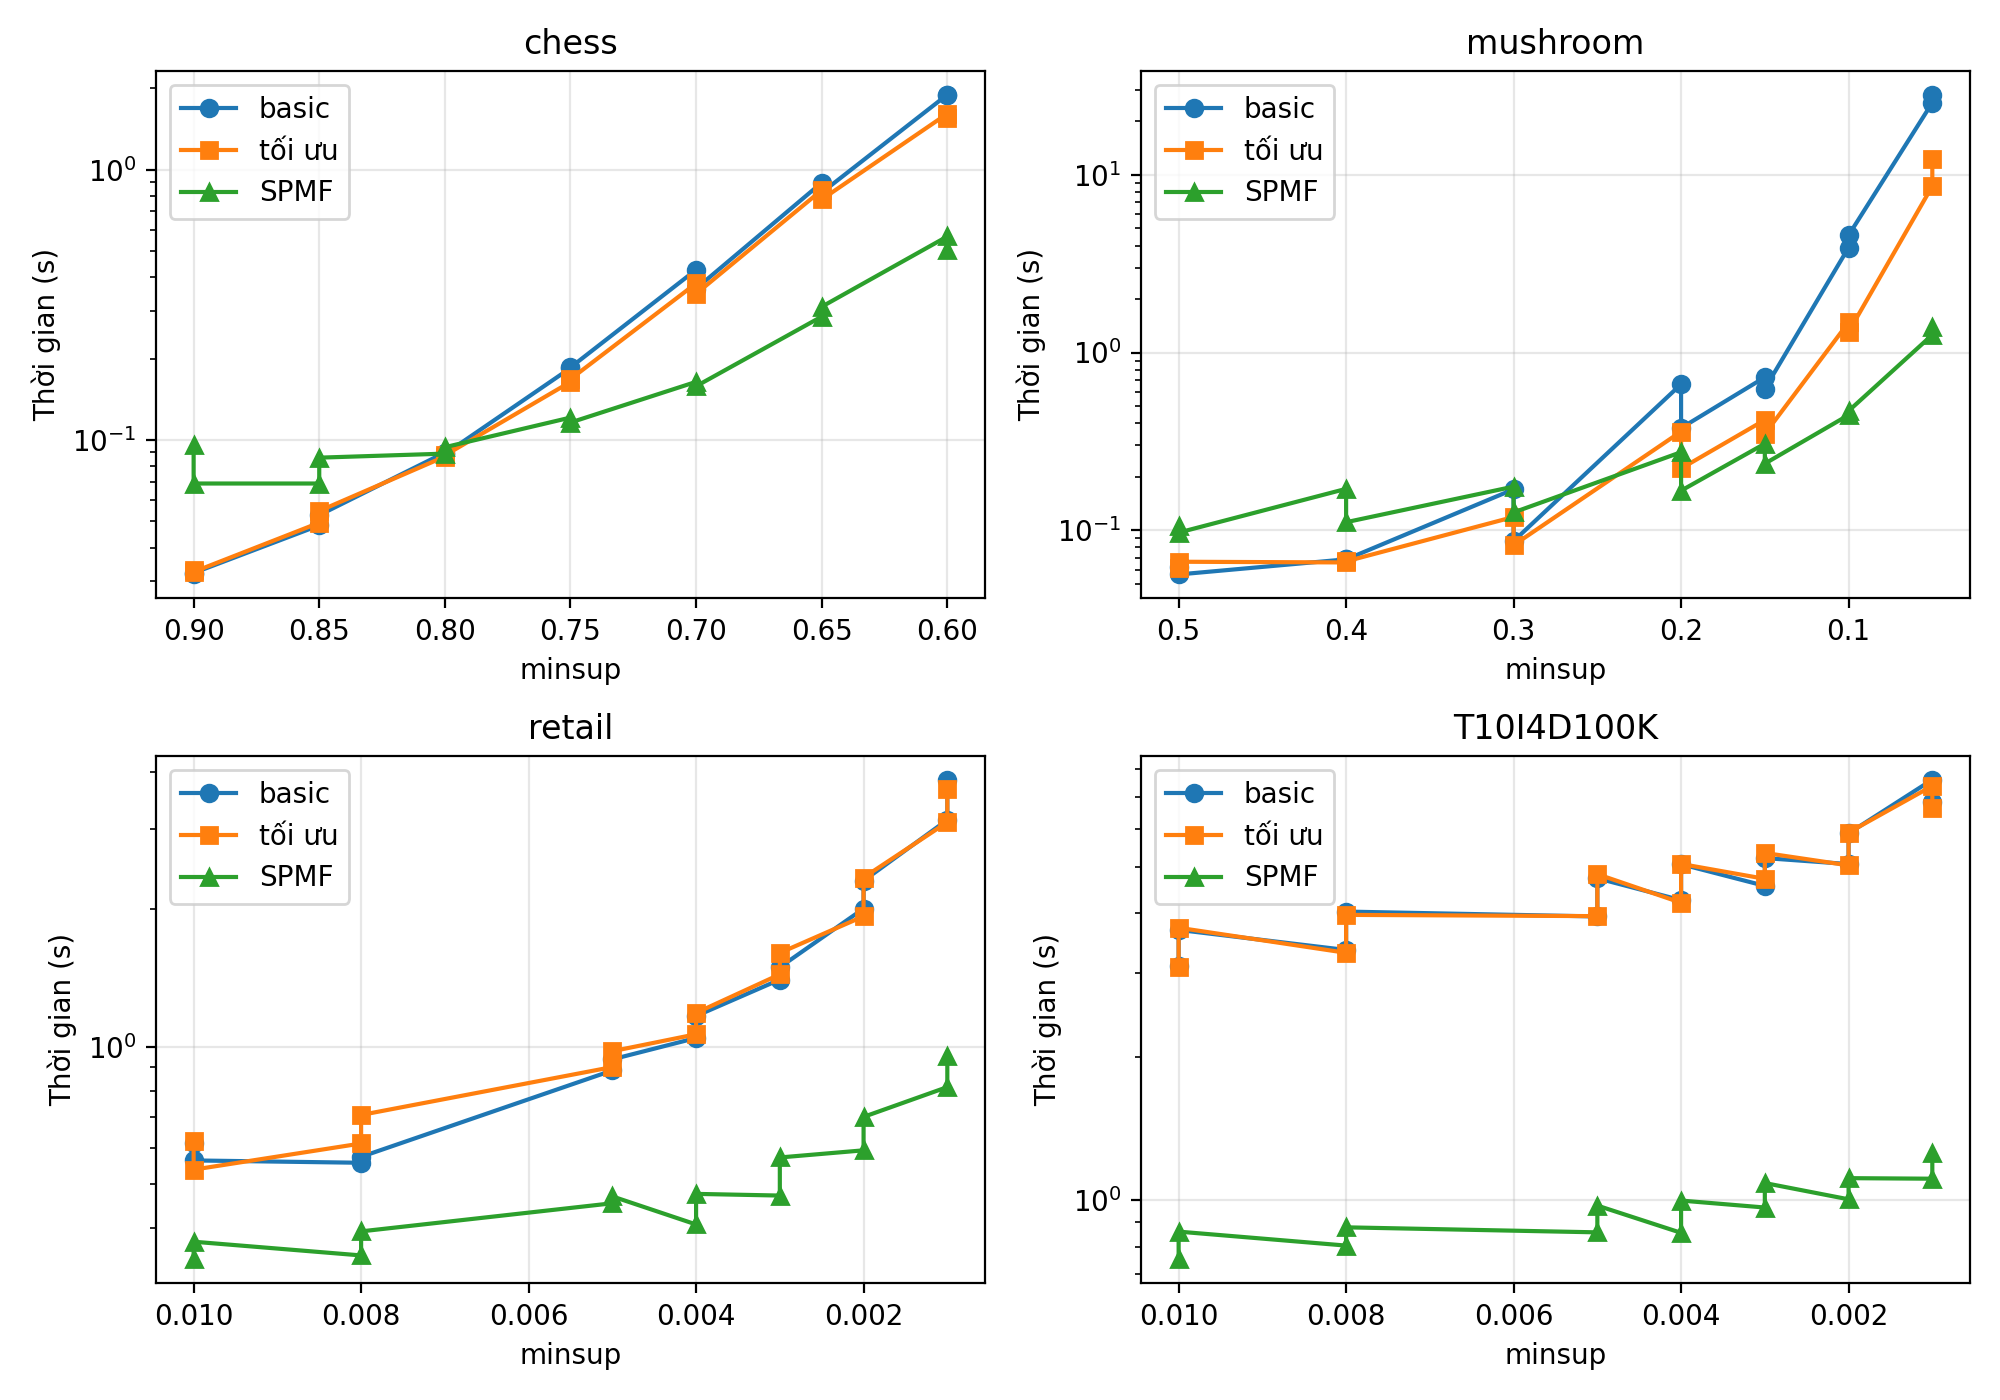

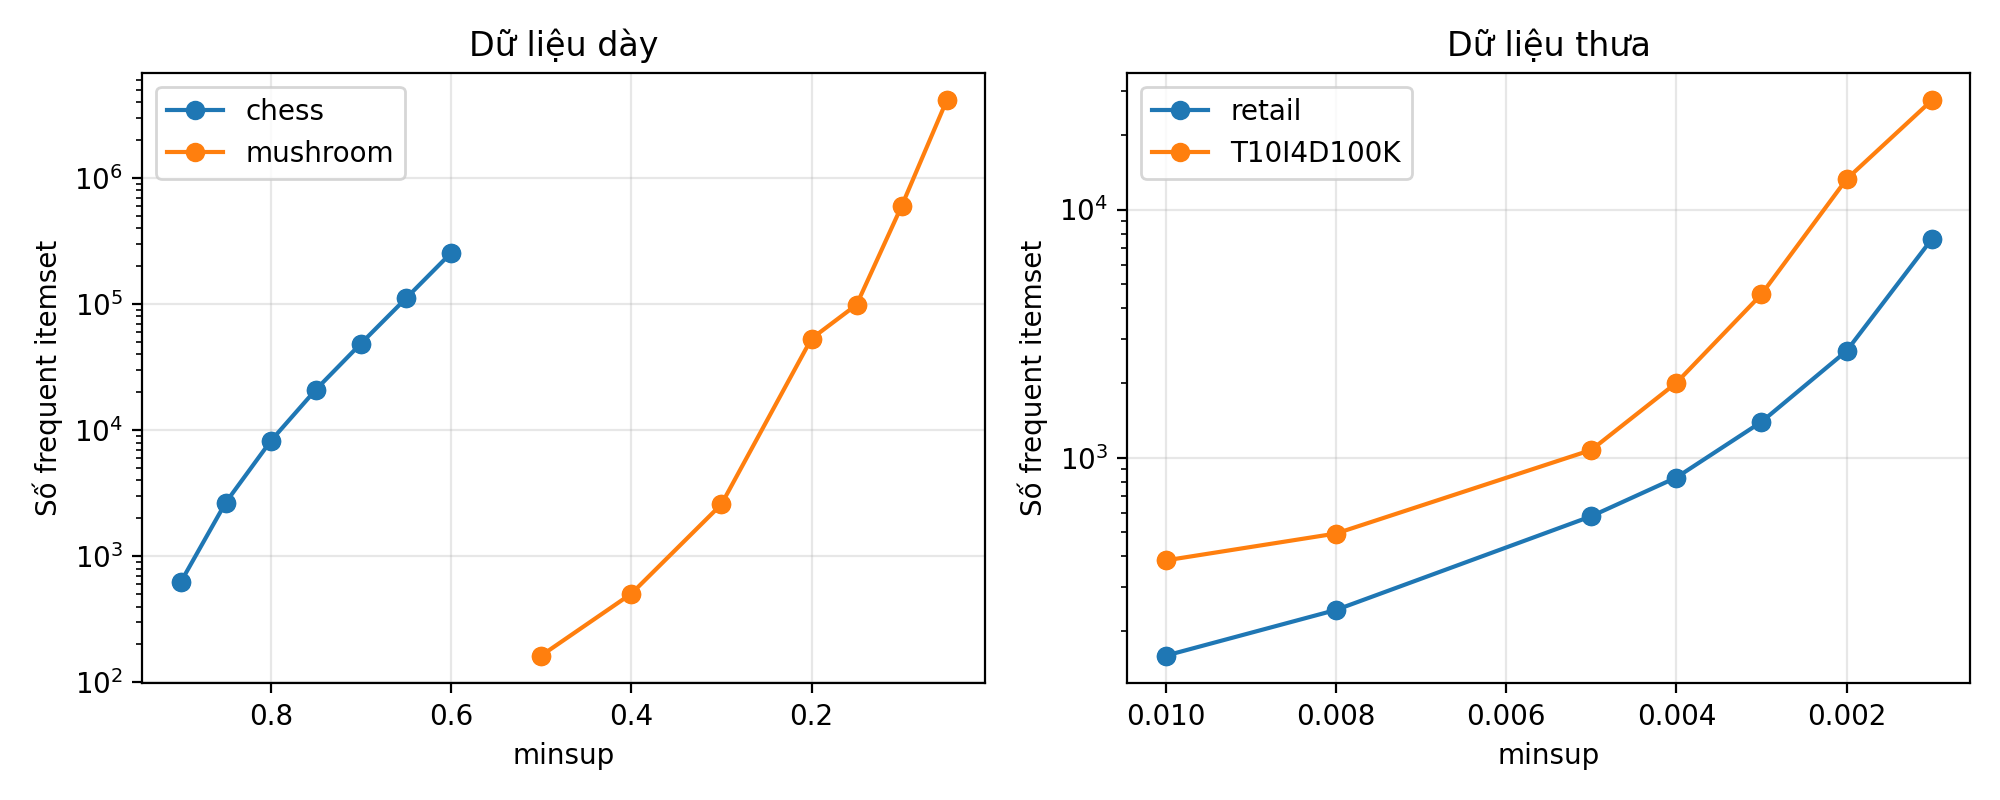

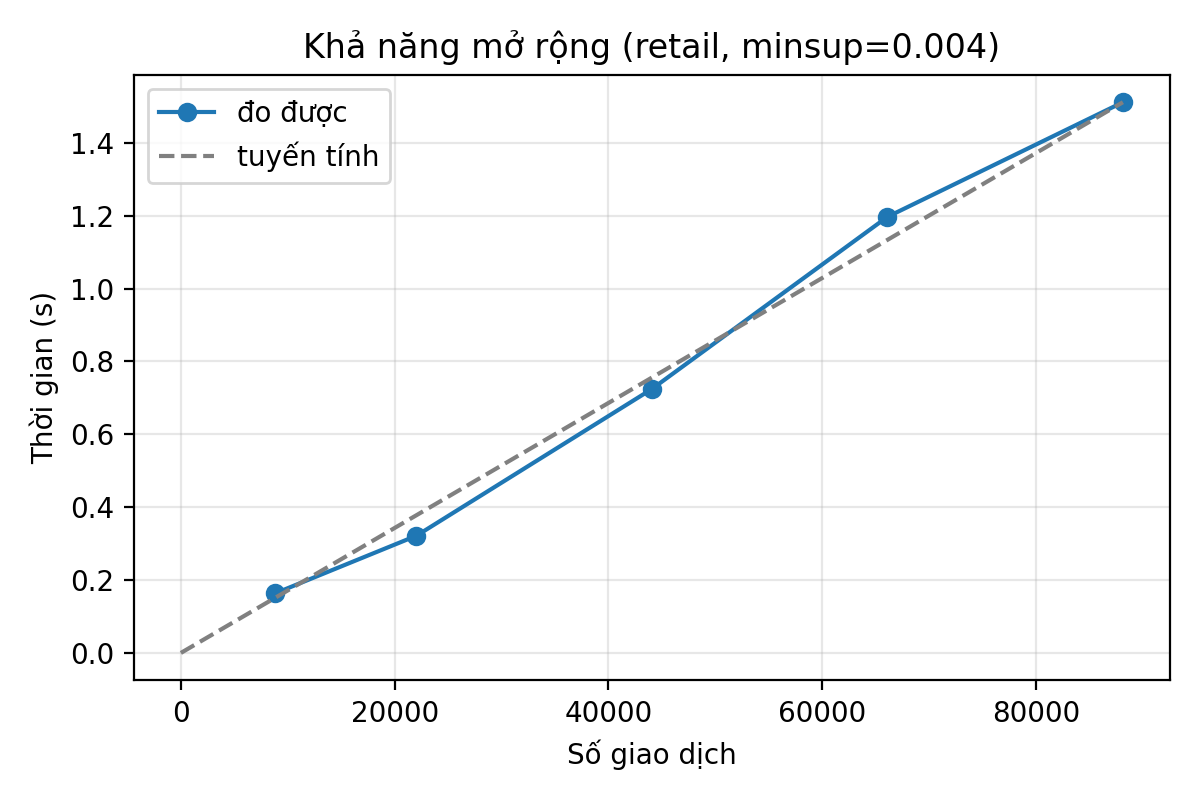

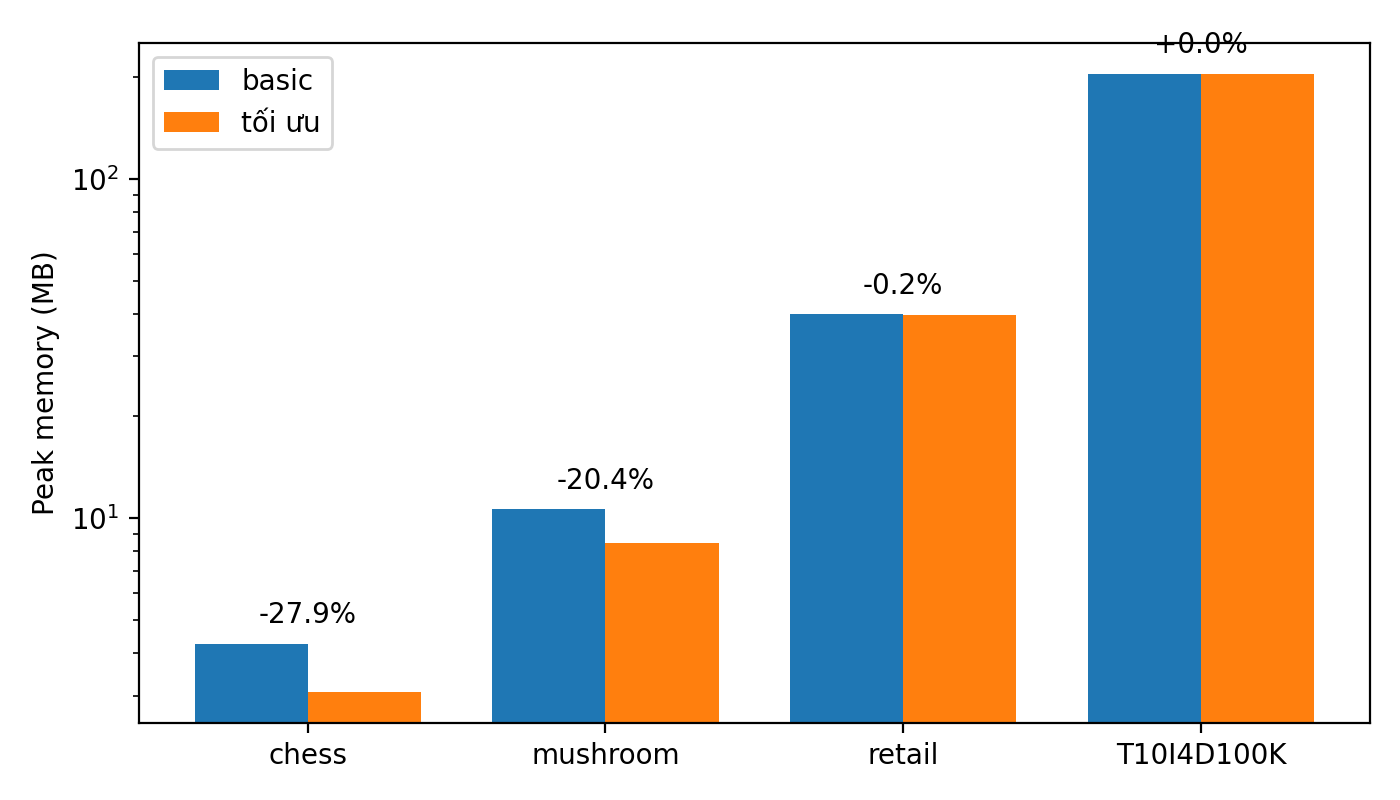

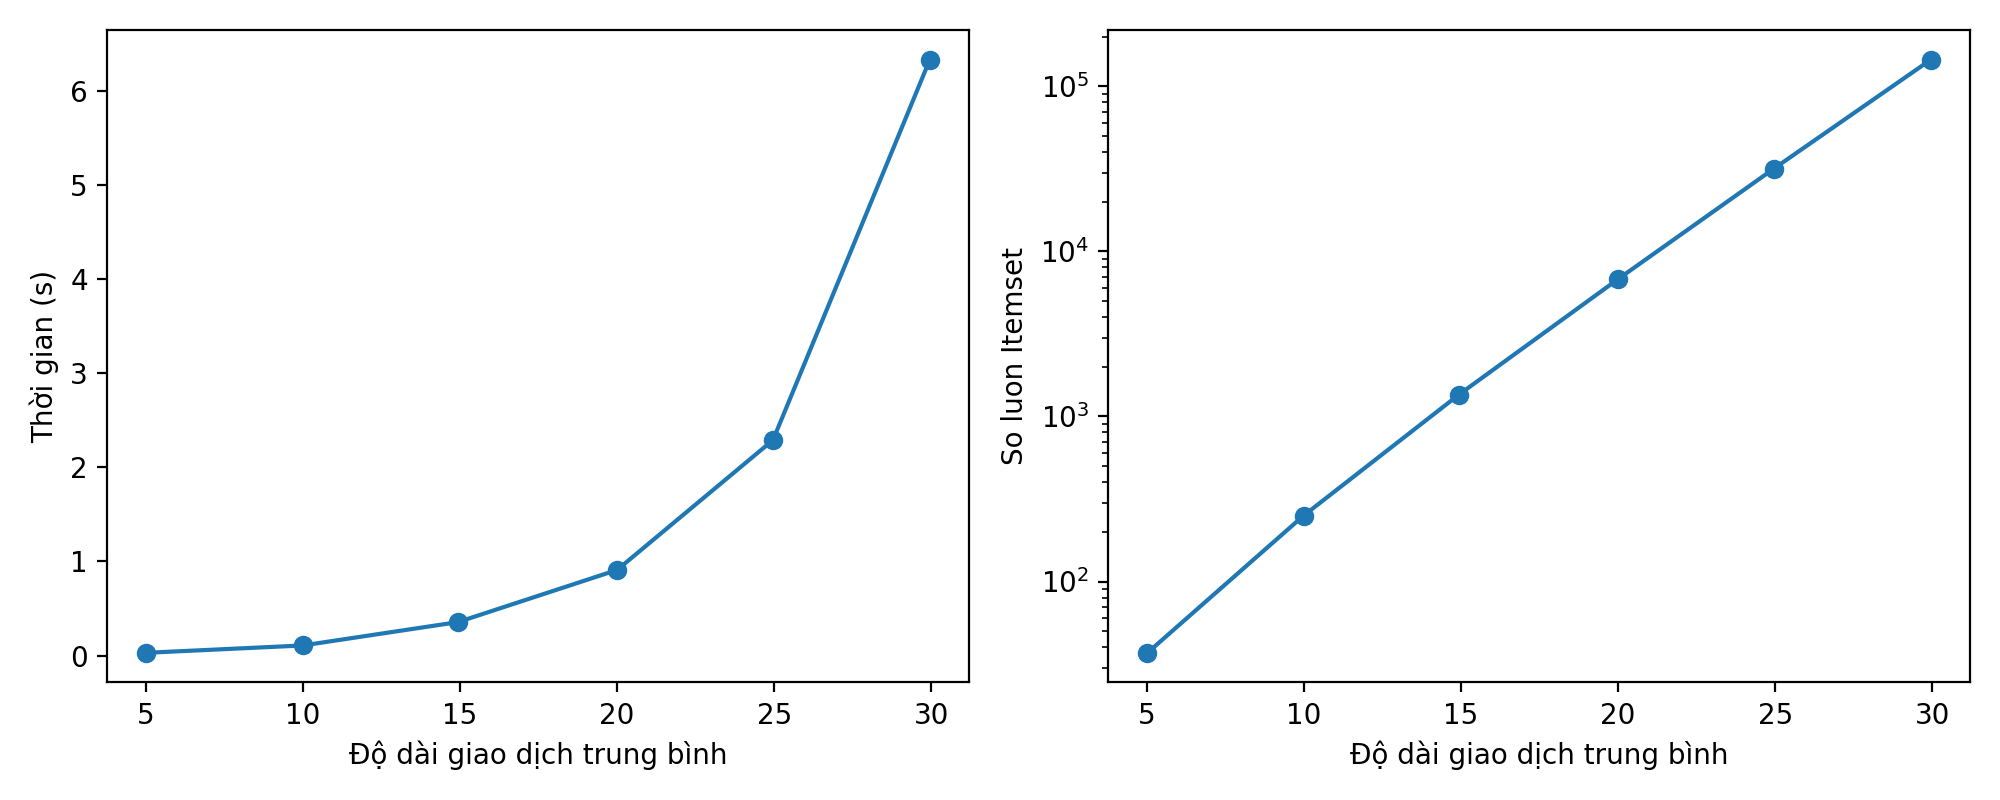

In [8]:
from IPython.display import Image

!python -m scripts.plot_ch2
for name in ["runtime", "itemsets", "scalability", "memory", "txlen"]:
    display(Image(f"docs/figures/{name}.png", width=800))

### Nhận xét (nửa B)
- Tối ưu single path giảm 21–25% bộ nhớ đỉnh trên dữ liệu dày (Chess, Mushroom), gần 0% trên dữ liệu thưa:
  đỉnh bộ nhớ chủ yếu là FP-tree gốc, mà tối ưu chỉ bớt được các conditional tree.
- Độ dài giao dịch tăng 6 lần làm thời gian tăng khoảng 180 lần và số itemset tăng khoảng 3.900 lần (phi tuyến),
  phù hợp với Lemma 2.2: giao dịch dài thì cây sâu và số tổ hợp bùng nổ.
- Khớp SPMF 100% trên cả 28 ca; chậm hơn SPMF khoảng 3–5 lần ở minsup thấp (tới 9 lần với Mushroom 0,05)
  do Python và cấu trúc node dạng object.
- Hướng tối ưu: FP-tree dạng mảng số nguyên; projected database cho dữ liệu thưa; mảng đếm cặp kiểu FP-growth*.

## 3. Ứng dụng 1
_(Thông viết phần này)_

## 4. Ứng dụng 2: Khai thác mẫu trong dữ liệu DNA

**Dữ liệu:** UCI Splice-junction Gene Sequences, gồm 3190 chuỗi DNA dài 60 nucleotide,
được gán nhãn EI (donor, ranh giới exon→intron), IE (acceptor, ranh giới intron→exon) hoặc N (không có ranh giới).

**Biến chuỗi thành giao dịch:** mỗi chuỗi là một giao dịch; mỗi item có dạng `P<vị trí>=<nucleotide>`,
với vị trí tính từ −30 đến +30 so với ranh giới (không có vị trí 0). Ví dụ: `P+1=G` là "G ở vị trí ngay sau ranh giới".
Vị trí phải ghép vào item, vì nếu chỉ lấy {A, C, G, T} thì chuỗi nào cũng chứa đủ 4 chữ.

In [9]:
from src.app2_bio import read_splice, to_transaction, load_groups

DATA_PATH = "data/app2/splice.data"
rows = read_splice(DATA_PATH)
label, seq = rows[0]
t = to_transaction(seq)
print(f"Mẫu đầu tiên ({label}): {seq}")
print(f"Giao dịch: {len(t)} item, quanh ranh giới: {t[27:33]}")

groups, code = load_groups(DATA_PATH)
print(f"{len(code)} item khác nhau | " + ", ".join(f"{k}: {len(v)} mẫu" for k, v in groups.items()))

Mẫu đầu tiên (EI): CCAGCTGCATCACAGGAGGCCAGCGAGCAGGTCTGTTCCAAGGGCCTTCGAGCCAGTCTG
Giao dịch: 60 item, quanh ranh giới: ['P-3=C', 'P-2=A', 'P-1=G', 'P+1=G', 'P+2=T', 'P+3=C']
240 item khác nhau | EI: 767 mẫu, IE: 768 mẫu, N: 1655 mẫu


### Chọn minsup
Mỗi vị trí có 4 khả năng, nên nếu DNA ngẫu nhiên thì mỗi item có support khoảng 25%.
Chạy FP-Growth riêng từng nhóm ở nhiều mức minsup để chọn mức chỉ giữ lại tín hiệu mạnh.

In [10]:
import pandas as pd
from src.algorithm.fpgrowth import fpgrowth
from src.config import to_min_count

table = {}
for minsup in [0.3, 0.5, 0.7]:
    table[minsup] = {label: len(fpgrowth(data, to_min_count(minsup, len(data))))
                     for label, data in groups.items()}
pd.DataFrame(table).T.rename_axis("minsup")

,EI,IE,N
minsup,,,
0.3,280,331,0
0.5,35,7,0
0.7,15,7,0


In [11]:
from src.utils import decode

for label in ["EI", "IE"]:
    data = groups[label]
    named = decode(fpgrowth(data, to_min_count(0.5, len(data))), code)
    top = sorted(named.items(), key=lambda x: x[1], reverse=True)[:7]
    print(f"\nTop của {label}:")
    for itemset, sup in top:
        print(f"  {sup / len(data):6.1%}  {itemset}")


Top của EI:
   99.7%  ('P+1=G',)
   99.0%  ('P+2=T',)
   99.0%  ('P+1=G', 'P+2=T')
   85.7%  ('P+5=G',)
   85.5%  ('P+1=G', 'P+5=G')
   85.0%  ('P+2=T', 'P+5=G')
   85.0%  ('P+1=G', 'P+2=T', 'P+5=G')

Top của IE:
   99.7%  ('P-1=G',)
   99.6%  ('P-2=A',)
   99.5%  ('P-1=G', 'P-2=A')
   78.9%  ('P-3=C',)
   78.9%  ('P-1=G', 'P-3=C')
   78.8%  ('P-2=A', 'P-3=C')
   78.8%  ('P-1=G', 'P-2=A', 'P-3=C')


In [12]:
from scripts.app2_check import show_exceptions
from src.app2_bio import read_splice_with_name

rows_named = read_splice_with_name(DATA_PATH)
show_exceptions(rows_named, "EI", 30, "GT")
show_exceptions(rows_named, "IE", 28, "AG")


EI: 8/767 mẫu không có GT
  thay vào đó là: Counter({'GC': 4, 'NN': 1, 'GG': 1, 'GA': 1, 'CA': 1})
  HUMALPI1-DONOR-42         NNNNN|NNNNN
  HUMAPRTA-DONOR-881        CGCAG|GCGAG
  HUMFVII-DONOR-70          TGCAG|GCGGG
  HUMINCPPS-DONOR-940       GCAGG|GGCCA
  HUMINCPPS-DONOR-2825      TGAGG|GAGTA
  HUMKER18-DONOR-4285       AAGAG|GCAAG
  HUMMYC3L-DONOR-2594       CTCTA|CAACG
  HUMTHB-DONOR-10723        TGCTG|GCAAG

IE: 4/768 mẫu không có AG
  thay vào đó là: Counter({'AC': 1, 'TG': 1, 'GG': 1, 'CA': 1})
  HUMAK1-ACCEPTOR-3918      CTTAC|AGAGC
  HUMAK1-ACCEPTOR-10488     CGCTG|AGGGC
  HUMALPI1-ACCEPTOR-124     CCTGG|CCAGC
  HUMINCPPS-ACCEPTOR-2712   ATACA|TGTAT


In [13]:
from scripts.app2_emerging import emerging
from src.utils import invert_code

name_of = invert_code(code)
for label in ["EI", "IE"]:
    rows_e = emerging(groups[label], groups["N"], 0.5)
    rows_e.sort(key=lambda r: (r[3], r[1]), reverse=True)
    df = pd.DataFrame([{"itemset": ", ".join(name_of[i] for i in r[0]),
                        label: f"{r[1]:.1%}", "N": f"{r[2]:.1%}",
                        "#N": r[4], "growth": round(r[3], 1)} for r in rows_e[:8]])
    display(df)

,itemset,EI,N,#N,growth
0,"P+1=G, P+2=T, P+4=A, P+5=G",63.8%,0.1%,1,1055.1
1,"P+1=G, P+2=T, P+5=G, P-1=G",67.1%,0.1%,2,555.6
2,"P+1=G, P+2=T, P+4=A, P-1=G",55.0%,0.2%,3,303.5
3,"P+1=G, P+2=T, P-1=G, P-2=A",50.3%,0.5%,8,104.1
4,"P+1=G, P+2=T, P+5=G",85.0%,0.9%,15,93.8
5,"P+2=T, P+5=G, P-1=G",67.1%,1.1%,18,61.7
6,"P+1=G, P+2=T, P+4=A",71.7%,1.2%,20,59.3
7,"P+2=T, P+4=A, P-1=G",55.0%,1.0%,17,53.6


,itemset,IE,N,#N,growth
0,"P-1=G, P-2=A, P-3=C",78.8%,2.3%,38,34.3
1,"P-1=G, P-2=A",99.5%,7.7%,127,13.0
2,"P-2=A, P-3=C",78.8%,6.1%,101,12.9
3,"P-1=G, P-3=C",78.9%,7.4%,123,10.6
4,P-2=A,99.6%,24.2%,400,4.1
5,P-1=G,99.7%,26.0%,431,3.8
6,P-3=C,78.9%,25.0%,413,3.2


Đã lưu docs/figures/app2_profile.png
Đã lưu docs/figures/app2_emerging.png


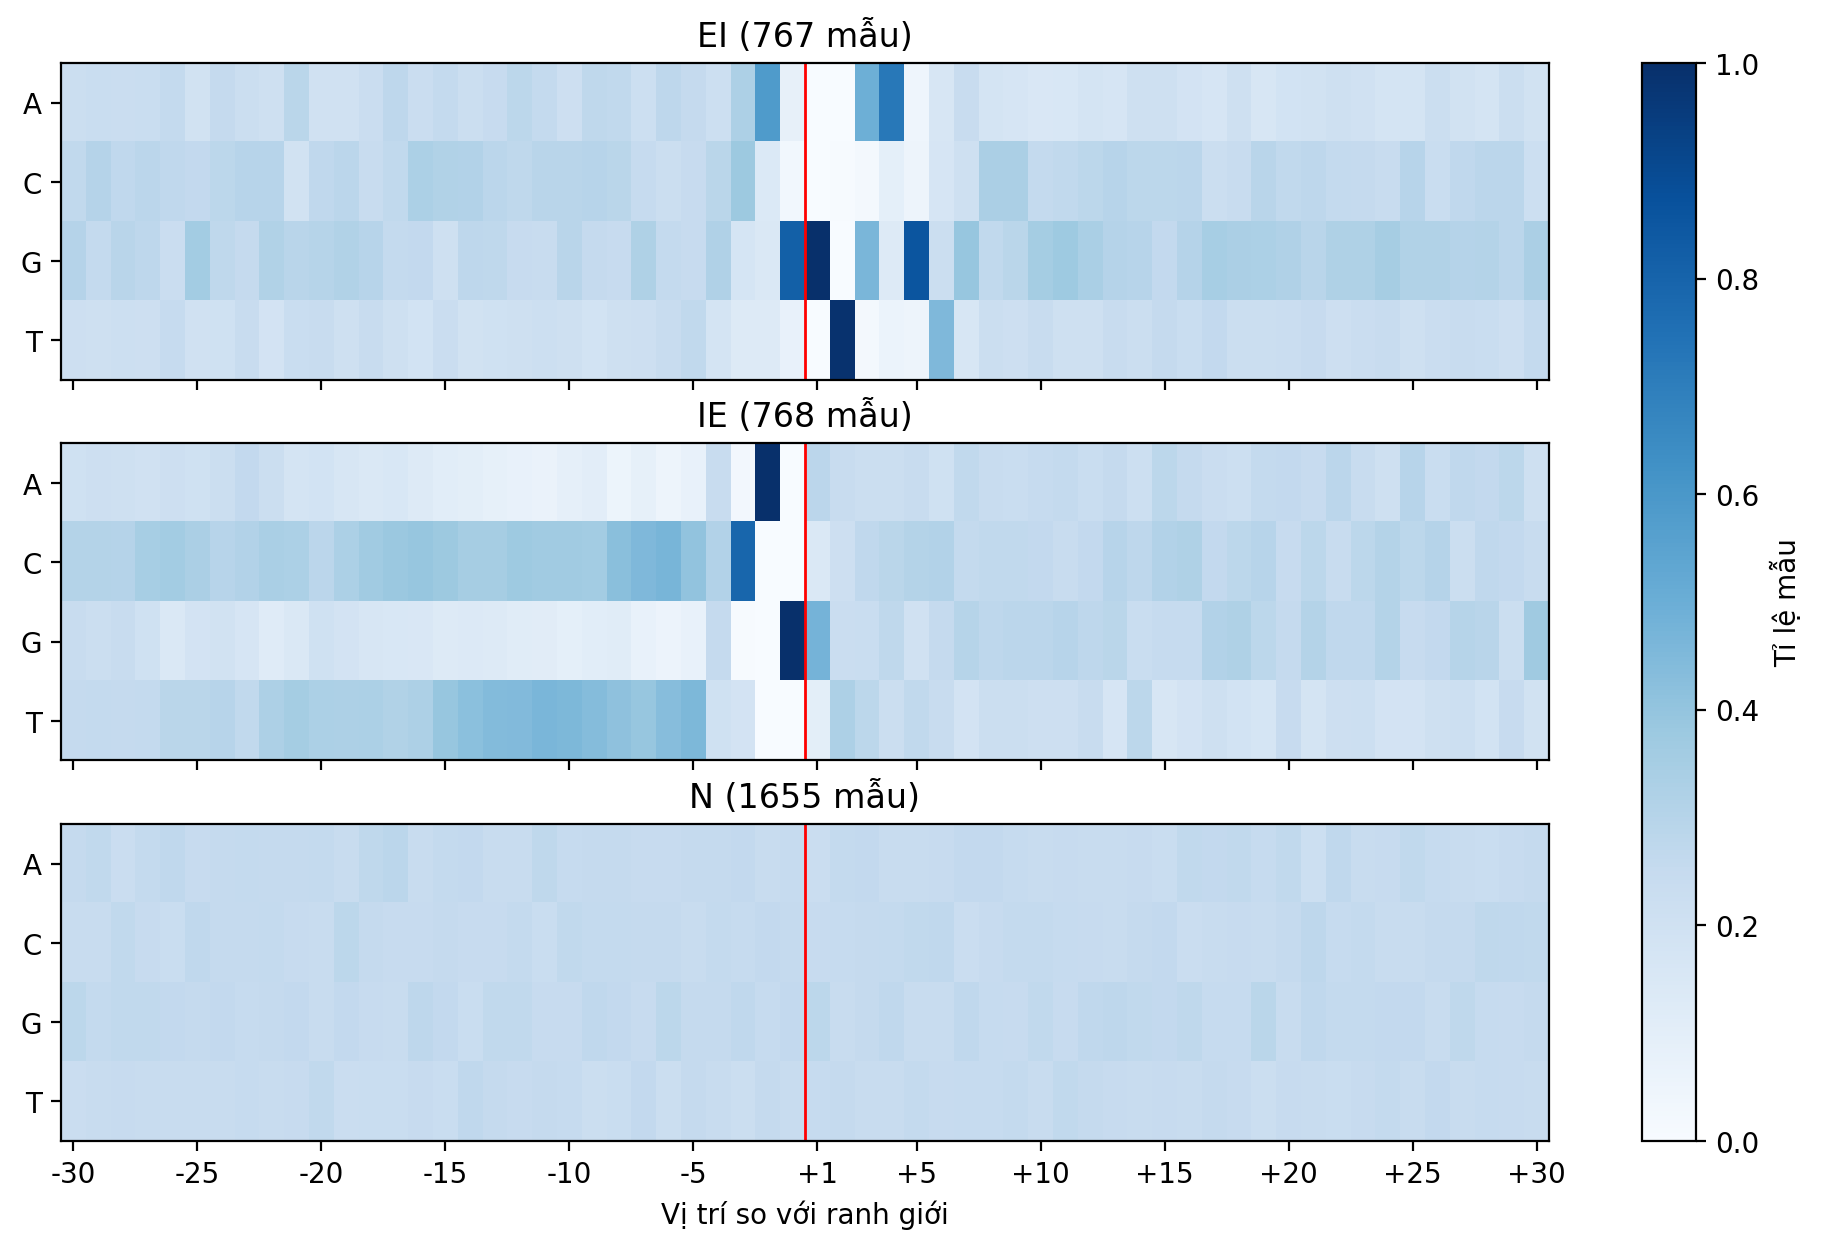

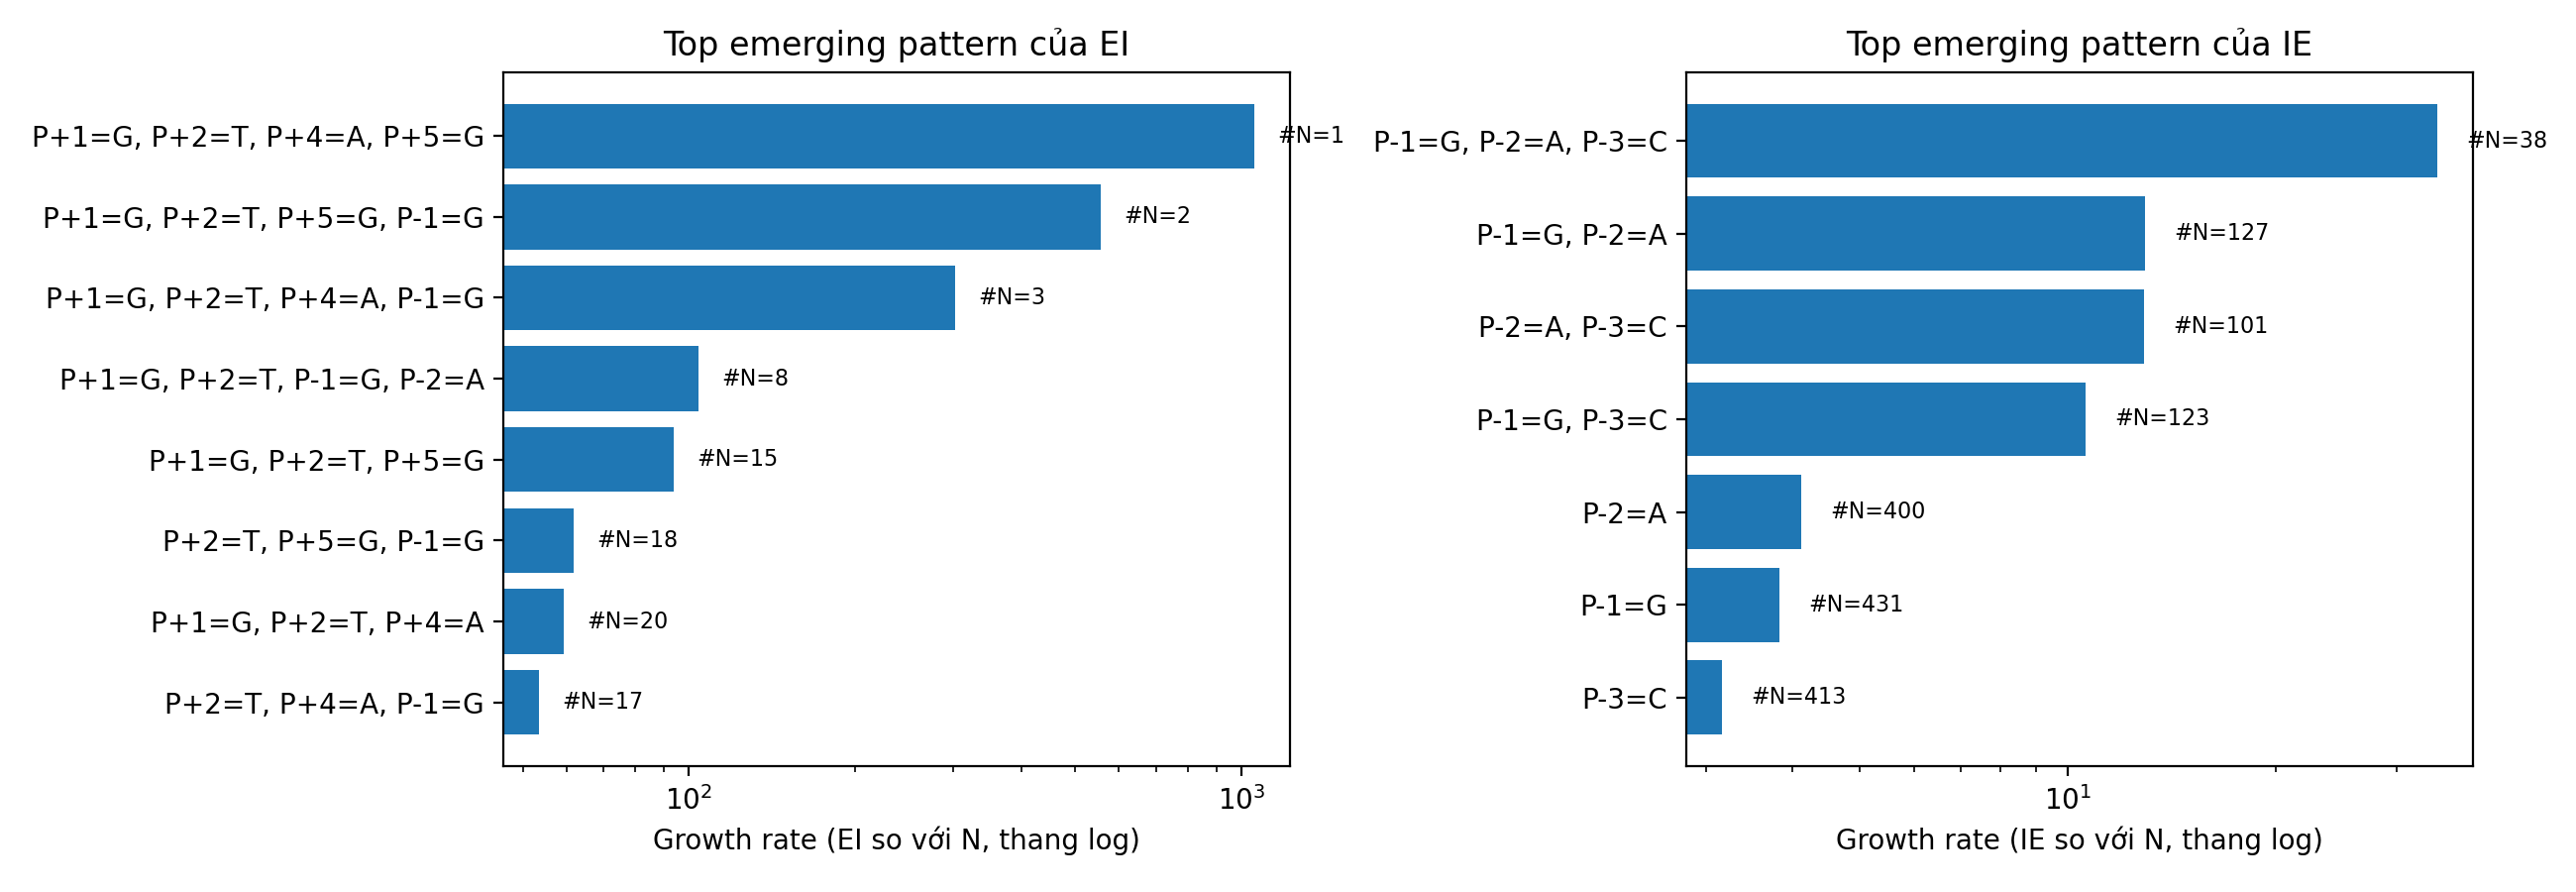

In [14]:
from IPython.display import Image
from scripts.app2_plot import plot_profile, plot_emerging

os.makedirs("docs/figures", exist_ok=True)
plot_profile(rows)
plot_emerging(groups, code)
display(Image("docs/figures/app2_profile.png", width=900))
display(Image("docs/figures/app2_emerging.png", width=900))

### Nhận xét

**Kết quả chính**
- FP-Growth tự tìm ra quy tắc GT–AG mà không được cung cấp kiến thức sinh học:
  {P+1=G, P+2=T} có trong 99.0% mẫu EI (donor), {P-2=A, P-1=G} có trong 99.5% mẫu IE (acceptor),
  gần với tỉ lệ 98.7% GT–AG được báo cáo trong tài liệu sinh học.
- Nhóm N không có itemset nào kể cả ở minsup 0.3, và mọi vị trí đều quanh mức ngẫu nhiên 25%:
  N là nhóm đối chứng tốt, chứng tỏ pattern của EI và IE không phải do tình cờ.

**Ngoại lệ**
- 4/767 mẫu EI bắt đầu bằng GC thay cho GT, khớp với loại intron GC–AG hiếm (khoảng 0.5–0.8% theo tài liệu).
- Ở 3/4 mẫu IE không có AG, cặp AG vẫn nằm cách ranh giới 2–4 vị trí: nhiều khả năng ranh giới bị chú thích lệch.

**Donor so với acceptor**
- Donor có vùng bảo tồn dài, từ −2 đến +6 (consensus AG|GTRAGT), nên tạo ra pattern rất đặc trưng:
  growth so với N lên tới hàng trăm.
- Acceptor chỉ có CAG bảo tồn mạnh, growth cao nhất chỉ 34. Tín hiệu còn lại là polypyrimidine tract
  (dải giàu C/T từ −20 đến −5, thấy rõ trên heatmap), nhưng bị chia giữa C và T nên không vượt minsup 0.5.
- Điều này giải thích vì sao trong file mô tả dữ liệu, hầu hết các thuật toán phân loại đều sai nhiều hơn ở IE.

**Hạn chế**
- Cách mã hóa `P<vị trí>=<nucleotide>` làm yếu các tín hiệu dạng "A hoặc G", "C hoặc T"
  (vị trí +3 của donor, polypyrimidine tract). Hướng cải tiến: thêm item gộp theo ký hiệu IUPAC (R, Y).
- Frequent itemset bỏ sót pattern hiếm dù có thật (ví dụ GC–AG chỉ chiếm 0.5%).
- Growth rate không đáng tin khi số mẫu N chứa pattern quá nhỏ (#N ≤ 3).

**Ứng dụng**
- Emerging pattern có thể dùng làm đặc trưng để nhận diện splice site trong chuỗi DNA mới.
  Có đánh đổi: pattern dài thì đặc trưng hơn nhưng bao phủ ít mẫu hơn.